<a href="https://www.kaggle.com/code/qwerty29544/selfmade-sigmoid-mseloss-based-model-auc-0-76?scriptVersionId=361417801" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import random


import sklearn
from sklearn.metrics import roc_curve, roc_auc_score

seed = 123
random.seed(seed)
np.random.seed(seed)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/playground-series-s3e23/sample_submission.csv
/kaggle/input/playground-series-s3e23/train.csv
/kaggle/input/playground-series-s3e23/test.csv


In [2]:
df = pd.read_csv(dirname + "/train.csv")
df['defects'] = df['defects'].replace([True, False], [1, 0])

In [3]:
df.head()

,id,loc,v(g),ev(g),iv(g),n,v,l,d,i,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,0,22.0,3.0,1.0,2.0,60.0,278.63,0.06,19.56,14.25,...,17,1,1,0,16.0,9.0,38.0,22.0,5.0,0
1,1,14.0,2.0,1.0,2.0,32.0,151.27,0.14,7.00,21.11,...,11,0,1,0,11.0,11.0,18.0,14.0,3.0,0
2,2,11.0,2.0,1.0,2.0,45.0,197.65,0.11,8.05,22.76,...,8,0,1,0,12.0,11.0,28.0,17.0,3.0,0
3,3,8.0,1.0,1.0,1.0,23.0,94.01,0.19,5.25,17.86,...,4,0,2,0,8.0,6.0,16.0,7.0,1.0,1
4,4,11.0,2.0,1.0,2.0,17.0,60.94,0.18,5.63,12.44,...,7,0,2,0,7.0,6.0,10.0,10.0,3.0,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101763 entries, 0 to 101762
Data columns (total 23 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 101763 non-null  int64  
 1   loc                101763 non-null  float64
 2   v(g)               101763 non-null  float64
 3   ev(g)              101763 non-null  float64
 4   iv(g)              101763 non-null  float64
 5   n                  101763 non-null  float64
 6   v                  101763 non-null  float64
 7   l                  101763 non-null  float64
 8   d                  101763 non-null  float64
 9   i                  101763 non-null  float64
 10  e                  101763 non-null  float64
 11  b                  101763 non-null  float64
 12  t                  101763 non-null  float64
 13  lOCode             101763 non-null  int64  
 14  lOComment          101763 non-null  int64  
 15  lOBlank            101763 non-null  int64  
 16  lo

In [5]:
df.describe()

,id,loc,v(g),ev(g),iv(g),n,v,l,d,i,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
count,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,...,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000,101763.000000
mean,50881.000000,37.347160,5.492684,2.845022,3.498826,96.655995,538.280956,0.111634,13.681881,27.573007,...,22.802453,1.773945,3.979865,0.196604,11.896131,15.596671,57.628116,39.249698,9.839549,0.226644
std,29376.592059,54.600401,7.900855,4.631262,5.534541,171.147191,1270.791601,0.100096,14.121306,22.856742,...,38.541010,5.902412,6.382358,0.998906,6.749549,18.064261,104.537660,71.692309,14.412769,0.418663
min,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,25440.500000,13.000000,2.000000,1.000000,1.000000,25.000000,97.670000,0.050000,5.600000,15.560000,...,7.000000,0.000000,1.000000,0.000000,8.000000,7.000000,15.000000,10.000000,3.000000,0.000000
50%,50881.000000,22.000000,3.000000,1.000000,2.000000,51.000000,232.790000,0.090000,9.820000,23.360000,...,14.000000,0.000000,2.000000,0.000000,11.000000,12.000000,30.000000,20.000000,5.000000,0.000000
75%,76321.500000,42.000000,6.000000,3.000000,4.000000,111.000000,560.250000,0.150000,18.000000,34.340000,...,26.000000,1.000000,5.000000,0.000000,16.000000,20.000000,66.000000,45.000000,11.000000,0.000000
max,101762.000000,3442.000000,404.000000,165.000000,402.000000,8441.000000,80843.080000,1.000000,418.200000,569.780000,...,2824.000000,344.000000,219.000000,43.000000,410.000000,1026.000000,5420.000000,3021.000000,503.000000,1.000000


In [6]:
Y = df['defects']
X = df.iloc[:, 1:-1]

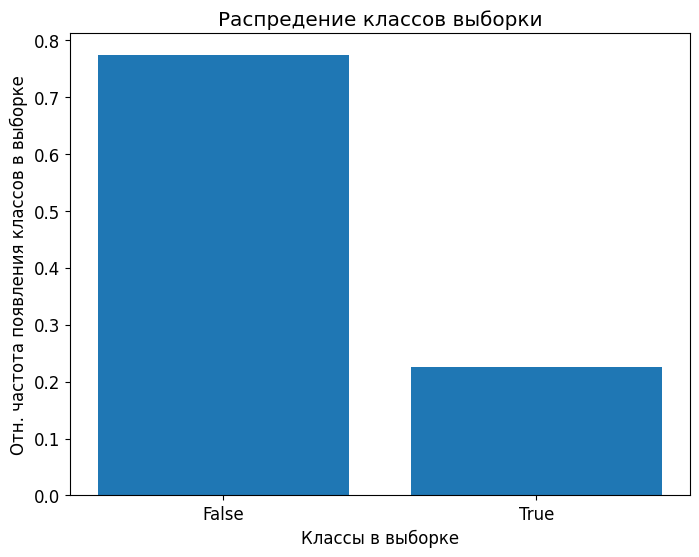

In [7]:
plt.figure(figsize=(8,6), dpi = 100)
plt.rc('font', size=12)
plt.rc('figure', titlesize=12)  # fontsize of the figure title
plt.bar(df['defects'].unique(), df['defects'].value_counts(normalize=True))
plt.xticks([])
plt.xticks([0.0, 1.0], ["False", "True"])
plt.title("Распредение классов выборки")
plt.xlabel("Классы в выборке")
plt.ylabel("Отн. частота появления классов в выборке")
plt.show()

<Figure size 6000x4800 with 0 Axes>

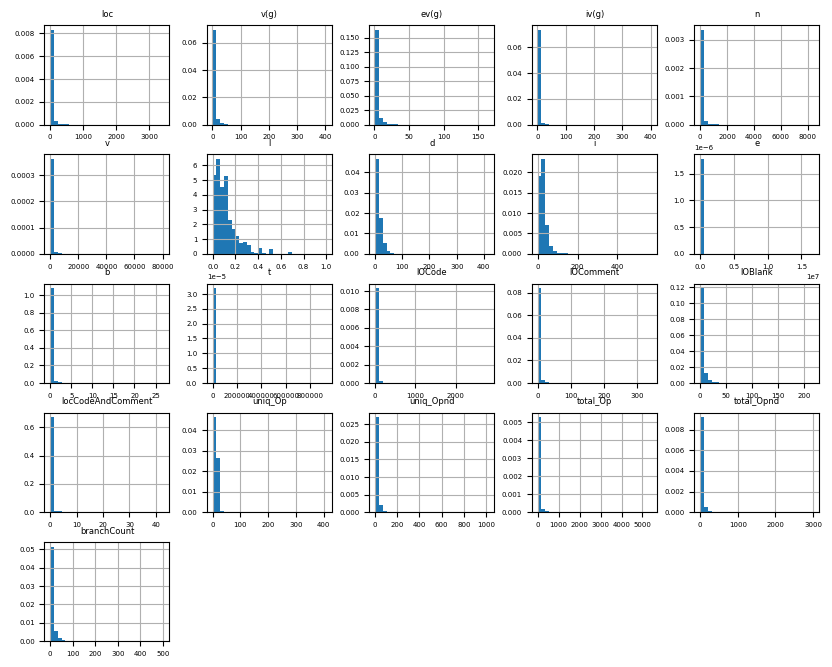

In [8]:
plt.figure(figsize = (20, 16), dpi = 300)
plt.rc('font', size=5)
plt.rc('figure', titlesize=2)  # fontsize of the figure title
df.iloc[:, 1:-1].hist(bins=30, figsize=(10, 8), density=True)
plt.show()

<Figure size 6000x4800 with 0 Axes>

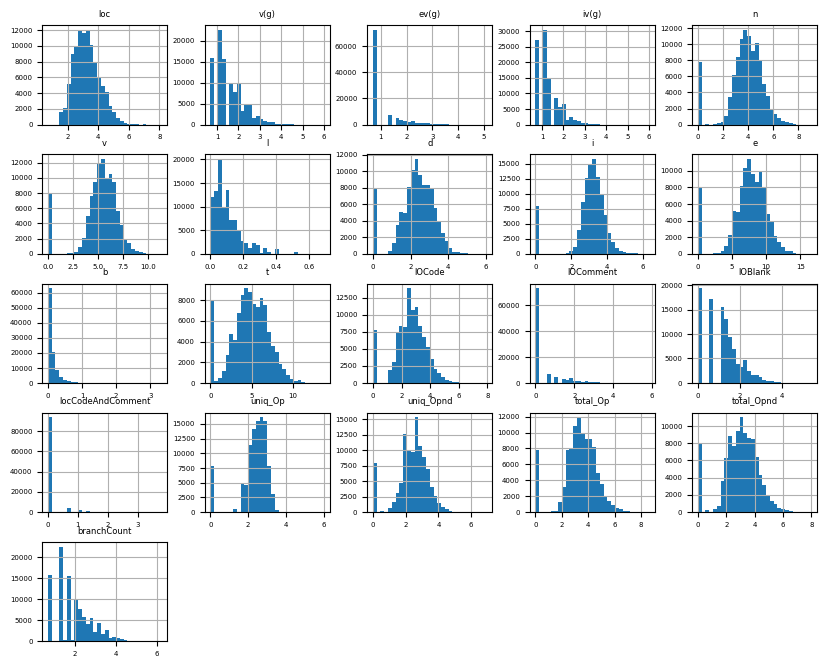

In [9]:
plt.figure(figsize = (20, 16), dpi = 300)
plt.rc('font', size=5)
plt.rc('figure', titlesize=2)  # fontsize of the figure title
df.iloc[:,1:-1].apply(lambda x: np.log(x + 1)).hist(bins=30, figsize=(10, 8))
plt.show()

In [10]:
# Реализуем преобразование Бокса-Кокса
subset = df.iloc[:, 1:-1]
new_log_cols = subset.apply(lambda x: np.log(x + 1))
new_log_cols.columns = ["log_" + x for x in subset.columns]
new_log_cols.head()

,log_loc,log_v(g),log_ev(g),log_iv(g),log_n,log_v,log_l,log_d,log_i,log_e,...,log_t,log_lOCode,log_lOComment,log_lOBlank,log_locCodeAndComment,log_uniq_Op,log_uniq_Opnd,log_total_Op,log_total_Opnd,log_branchCount
0,3.135494,1.386294,0.693147,1.098612,4.110874,5.633467,0.058269,3.023347,2.724580,8.603332,...,5.716073,2.890372,0.693147,0.693147,0.0,2.833213,2.302585,3.663562,3.135494,1.791759
1,2.708050,1.098612,0.693147,1.098612,3.496508,5.025655,0.131028,2.079442,3.096030,6.843441,...,3.971046,2.484907,0.000000,0.693147,0.0,2.484907,2.484907,2.944439,2.708050,1.386294
2,2.484907,1.098612,0.693147,1.098612,3.828641,5.291544,0.104360,2.202765,3.168003,7.470230,...,4.589549,2.197225,0.000000,0.693147,0.0,2.564949,2.484907,3.367296,2.890372,1.386294
3,2.197225,0.693147,0.693147,0.693147,3.178054,4.553982,0.173953,1.832581,2.937043,6.162599,...,3.307253,1.609438,0.000000,1.098612,0.0,2.197225,1.945910,2.833213,2.079442,0.693147
4,2.484907,1.098612,0.693147,1.098612,2.890372,4.126166,0.165514,1.891605,2.598235,5.904462,...,3.059176,2.079442,0.000000,1.098612,0.0,2.079442,1.945910,2.397895,2.397895,1.386294


In [11]:
X = pd.concat([X, new_log_cols], axis = 1)
X.head()

,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,log_t,log_lOCode,log_lOComment,log_lOBlank,log_locCodeAndComment,log_uniq_Op,log_uniq_Opnd,log_total_Op,log_total_Opnd,log_branchCount
0,22.0,3.0,1.0,2.0,60.0,278.63,0.06,19.56,14.25,5448.79,...,5.716073,2.890372,0.693147,0.693147,0.0,2.833213,2.302585,3.663562,3.135494,1.791759
1,14.0,2.0,1.0,2.0,32.0,151.27,0.14,7.00,21.11,936.71,...,3.971046,2.484907,0.000000,0.693147,0.0,2.484907,2.484907,2.944439,2.708050,1.386294
2,11.0,2.0,1.0,2.0,45.0,197.65,0.11,8.05,22.76,1754.01,...,4.589549,2.197225,0.000000,0.693147,0.0,2.564949,2.484907,3.367296,2.890372,1.386294
3,8.0,1.0,1.0,1.0,23.0,94.01,0.19,5.25,17.86,473.66,...,3.307253,1.609438,0.000000,1.098612,0.0,2.197225,1.945910,2.833213,2.079442,0.693147
4,11.0,2.0,1.0,2.0,17.0,60.94,0.18,5.63,12.44,365.67,...,3.059176,2.079442,0.000000,1.098612,0.0,2.079442,1.945910,2.397895,2.397895,1.386294


In [12]:
train_ratio = 0.8
random_order = np.random.permutation(len(X))

# take only logs data
X = X[[x for x in X.columns if 'log' in x]] 
train_idxes = random_order[:int(train_ratio * len(random_order))]
test_idxes = random_order[int(train_ratio * len(random_order)):]
X_train = X.iloc[train_idxes,:]
X_test = X.iloc[test_idxes,:]
Y_train = Y.iloc[train_idxes]
Y_test = Y.iloc[test_idxes]

In [13]:
def TP(y_true, y_model):
    return np.sum(y_true * np.round(y_model, 0))


def FN(y_true, y_model):
    return np.sum(y_true * (1 - np.round(y_model, 0)))


def FP(y_true, y_model):
    return np.sum((1 - y_true) * np.round(y_model, 0))


def TN(y_true, y_model):
    return np.sum((1 - y_true) * (1 - np.round(y_model, 0)))


def accuracy(y_true, y_model):
    return 1 - np.mean(np.round(np.abs(y_true - np.round(y_model, 0)), 2))
    

def precision(y_true, y_model):
    TP_score = TP(y_true, np.round(y_model, 0))
    FP_score = FP(y_true, np.round(y_model, 0))
    return TP_score / (TP_score + FP_score)
    
    
def recall(y_true, y_model):
    TP_score = TP(y_true, np.round(y_model, 0))
    FN_score = FN(y_true, np.round(y_model, 0))
    return TP_score / (TP_score + FN_score)


def FPR(y_true, y_model):
    TN_score = TN(y_true, np.round(y_model, 0))
    FP_score = FP(y_true, np.round(y_model, 0))
    return FP_score / (FP_score + TN_score)


def F(y_true, y_model, beta = 1):
    prec_score = precision(y_true, y_model)
    rec_score = recall(y_true, y_model)
    return (1 + beta**2) * (prec_score * rec_score) / ((beta ** 2) * prec_score + rec_score)

In [14]:
class binary_classificator:
    def __init__(self):
        self.weights = 0
        self.data = 0     # X
        self.response = 0 # Y
        self.train_accuracy = 0
        self.train_F1 = 0
    
    # Сигмоидальная функция активации
    def _fout(self, x):
        return 1/(1 + np.exp(-x))
    
    # Функция потерь
    def _loss(self, y_true, y_model):
        return np.mean((y_true - y_model)**2)
    
    # Отклик модели
    def _model_response(self):
        # sigma(X @ W)
        return self._fout(self.weights.dot(self.data.T))
    
    # Обучение модели
    def fit(self, data_x, data_y, loss = "mse", epstol = 0.001, alpha = 0.001, niter = 1000):
        # Сохранение данных с фиктивной единицей
        self.data = np.concatenate([np.ones(len(data_x)).reshape(-1, 1), data_x], axis = 1)
        # Сохранение реальных меток задачи
        self.response = data_y
        # Инициализация весов
        self.weights = np.random.uniform(-1/len(data_x), 1/len(data_x), self.data.shape[1])
        
        # Цикл обучения
        for n in tqdm(range(niter)):
            # Ответ модели на текущем шаге обучения
            model_resp = self._model_response()
            
            # Проверка условия точности
            if self._loss(self.response, model_resp) < epstol:
                break # Если проходим проверку то выход из обучения
            
            # Шаг обновления весов
            # (X @ W^{k} - y) * sigma * (1 - sigma)
            vec_err = model_resp * (1 - model_resp) * (model_resp - self.response)   
            # W^{k+1} = W^{k} - alpha / N * (X.T @ ((X @ W^{k} - y) * sigma * (1 - sigma)))
            self.weights = self.weights - (alpha * (1 / len(self.data)) * (self.data.T @ vec_err))
        
        model_resp = self._model_response()
        # Подсчет точности на тренировочном датасете
        self.train_accuracy = accuracy(self.response, model_resp)
        # Подсчет метрики F1 на тренировочном датасете
        self.train_F1 = F(self.response, np.round(model_resp, 0))
            
    # Предсказание на новых данных
    def predict(self, data_rows):
        X_rows = np.concatenate([np.ones(len(data_rows)).reshape(-1, 1), data_rows], axis = 1)
        return self._fout(self.weights.dot(X_rows.T))
    
    def __str__(self):
        return f"model bias: {self.weights[0]}" + \
    f"\n\nmodel weights:\n {self.weights[1:]}" + \
    f"\n\nF1 score on train = {self.train_F1}" + \
    f"\n\naccuracy on train = {self.train_accuracy}"

In [15]:
model1 = binary_classificator()
model1.fit(X_train, Y_train, alpha = 0.005, niter = 10000)
print(model1)

100%|██████████| 10000/10000 [01:05<00:00, 151.74it/s]

model bias: -0.28319108668543574

model weights:
 [-0.07421097  0.07887641  0.01588876  0.11412612 -0.05712646 -0.23294935
 -0.06596349 -0.04672189 -0.2677979  -0.21160358  0.14169692  0.40092524
  0.14725934  0.30486912  0.32477548  0.10738049 -0.26922387  0.02460165
  0.03458161  0.13504916  0.07906768]

F1 score on train = 0.3653080215894287

accuracy on train = 0.7905539859968063


# Результат работы модели на тестовых данных

In [16]:
Y_pred_proba = model1.predict(X_test)
Y_pred = (Y_pred_proba > 0.5) * 1.0

In [17]:
F(Y_test, Y_pred)

0.3684674104521433

In [18]:
accuracy(Y_test, Y_pred)

0.7886306686974893

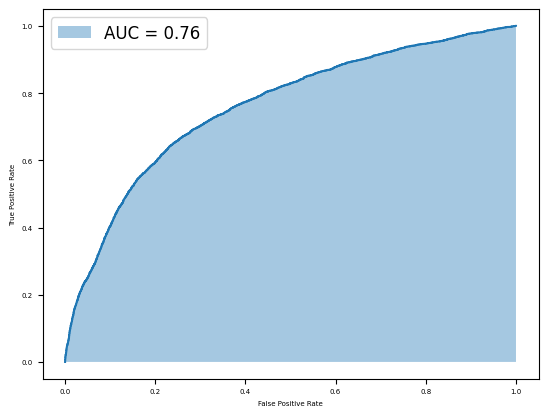

In [19]:
AUC = roc_auc_score(Y_test, Y_pred_proba)
fpr, tpr, _ = roc_curve(Y_test, Y_pred_proba)

plt.figure()
plt.plot(fpr, tpr)
plt.rc('font', size=12)
plt.rc('figure', titlesize=12)  # fontsize of the figure title
plt.fill_between(fpr, tpr, step="mid", interpolate=True, alpha=0.4, label = "AUC = " + str(round(AUC, 2)))
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# Обучение и прогон модели на train.csv + submission на выборке test.csv

In [20]:
seed = 123
random.seed(seed)
np.random.seed(seed)

df_train = pd.read_csv(dirname + "/train.csv")
df_train['defects'] = df_train['defects'].replace([True, False], [1, 0])

df_test = pd.read_csv(dirname + "/test.csv")

df_train.iloc[:, 1:-1] = df_train.iloc[:, 1:-1].apply(lambda x: np.log(x + 1))
df_test.iloc[:, 1:] = df_test.iloc[:, 1:].apply(lambda x: np.log(x + 1))

In [21]:
model_result = binary_classificator()
model_result.fit(df_train.iloc[:, 1:-1], df_train.iloc[:, -1], alpha = 0.005, niter = 10000)
print(model_result)

100%|██████████| 10000/10000 [01:18<00:00, 127.43it/s]


model bias: -0.2823870835924357

model weights:
 [-0.06949165  0.07788456  0.01691382  0.11377523 -0.05688965 -0.2328376
 -0.06584127 -0.04910557 -0.26709946 -0.21277959  0.14285737  0.39982798
  0.14829121  0.30562964  0.32594599  0.10637115 -0.26982991  0.02490894
  0.03482138  0.13521054  0.07794199]

F1 score on train = 0.36982109227871934

accuracy on train = 0.7895502294547134


In [22]:
Y_pred_proba = model_result.predict(df_test.iloc[:, 1:])
submission = pd.DataFrame(data = df_test.id, columns = ["id"])
submission["defects"] = Y_pred_proba
submission.to_csv("submission.csv", index=False)

# Sklearn models

In [23]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

In [24]:
model = GridSearchCV(GradientBoostingClassifier(), 
                     param_grid = {'n_estimators': [50, 60, 70, 80, 90, 100]}, 
                     cv = 4, n_jobs=-1, scoring = "roc_auc")

In [25]:
model.fit(df_train.iloc[:, 1:-1], df_train.iloc[:, -1])

GridSearchCV(cv=4, estimator=GradientBoostingClassifier(), n_jobs=-1,
             param_grid={'n_estimators': [50, 60, 70, 80, 90, 100]},
             scoring='roc_auc')

In [26]:
model.cv_results_

{'mean_fit_time': array([17.86280662, 21.29227042, 24.92570776, 28.4143731 , 31.7746582 ,
        35.09292358]),
 'std_fit_time': array([0.02621759, 0.08448688, 0.17540346, 0.13569607, 0.13141708,
        0.0491591 ]),
 'mean_score_time': array([0.05354083, 0.05852145, 0.06006449, 0.06425804, 0.06720787,
        0.06479055]),
 'std_score_time': array([0.00106201, 0.0030916 , 0.00064517, 0.00347969, 0.00075435,
        0.00754248]),
 'param_n_estimators': masked_array(data=[50, 60, 70, 80, 90, 100],
              mask=[False, False, False, False, False, False],
        fill_value='?',
             dtype=object),
 'params': [{'n_estimators': 50},
  {'n_estimators': 60},
  {'n_estimators': 70},
  {'n_estimators': 80},
  {'n_estimators': 90},
  {'n_estimators': 100}],
 'split0_test_score': array([0.7884205 , 0.78863945, 0.78891733, 0.78894405, 0.78915908,
        0.78904015]),
 'split1_test_score': array([0.79403083, 0.79422622, 0.79426047, 0.79435513, 0.79428934,
        0.79442339]),
 's

In [27]:
model.best_score_

0.791101757854163

In [28]:
Y_pred_proba = model.predict(df_test.iloc[:, 1:])
submission = pd.DataFrame({"id": df_test.id, "defects": Y_pred_proba})
submission.to_csv("submission.csv", index=False)